# Loading Packages

In [3]:
!pip install --upgrade numpy==1.21

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 44.0 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.19.0
    Uninstalling numpy-1.19.0:
      Successfully uninstalled numpy-1.19.0
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorboard 2.6.0 requires google-auth-oauthlib<0.5,>=0.4.1, but you have google-auth-oauthlib 1.0.0 which is incompatible.
tensorboard 2.6.0 requires tensorboard-data-server<0.7.0,>=0.6.0, but you have tensorboard-data-server 0.7.0 which is incompatible.
xarray-einstats 0.5.1 requires xarray>=2022.09.0, but you have xarray 0.21.1 which is incompatible.

[notice] A new release of pip is

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import hddm
import pickle

print(hddm.__version__)

0.9.9


# Loading Data

In [2]:
data = hddm.load_csv("../data/HDDM_data.csv")
data.head(10)

,subj_idx,rt,experimental_treatment_selected,trial_index,condition,risk,gain,no_effect,Optimize,Q1,Q3,IQR,response,domain,subj_idx.1
0,AyjDXCOl,1.948725,True,10,Attention (Concentration),35,45,20,0.0,618.4525,1380.565,762.1125,1,1,110
1,AyjDXCOl,1.994525,True,13,Attention (Concentration),15,20,65,0.0,618.4525,1380.565,762.1125,1,1,110
2,AyjDXCOl,0.558885,True,16,Attention (Concentration),25,70,5,0.0,618.4525,1380.565,762.1125,1,1,110
3,AyjDXCOl,1.670090,False,19,Attention (Concentration),25,45,30,0.0,618.4525,1380.565,762.1125,0,1,110
4,AyjDXCOl,1.499020,False,22,Attention (Concentration),45,30,25,0.0,618.4525,1380.565,762.1125,0,1,110
5,AyjDXCOl,0.955915,True,25,Attention (Concentration),5,70,25,0.0,618.4525,1380.565,762.1125,1,1,110
6,AyjDXCOl,1.564935,False,28,Attention (Concentration),45,45,10,0.0,618.4525,1380.565,762.1125,0,1,110
7,AyjDXCOl,0.793320,False,31,Attention (Concentration),25,55,20,0.0,618.4525,1380.565,762.1125,0,1,110
8,AyjDXCOl,0.845140,False,34,Attention (Concentration),60,15,25,0.0,618.4525,1380.565,762.1125,0,1,110
9,AyjDXCOl,1.098485,False,37,Attention (Concentration),25,10,65,0.0,618.4525,1380.565,762.1125,0,1,110


In [3]:
unique_values_count = data['subj_idx'].nunique()

print(unique_values_count)

563


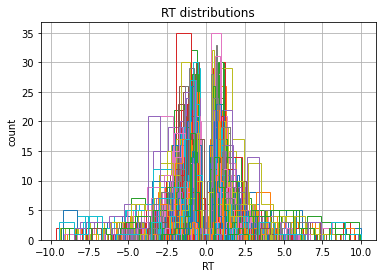

In [3]:
# If we want to draw the RT distributions for each participant
data = hddm.utils.flip_errors(data)
fig = plt.figure()
ax = fig.add_subplot(111, xlabel='RT', ylabel='count',
                     title='RT distributions')
for i, subj_data in data.groupby('subj_idx'):
    subj_data.rt.hist(bins=20, histtype='step', ax=ax)

plt.savefig('hddm_outputs/hddm_demo_fig_00.pdf')

# Simplest Analysis (No parameter dependencies)

## Run four-parameter DDM

In [4]:
m = hddm.HDDM(data, include=('v', 'a', 't', 'z'))

No model attribute --> setting up standard HDDM
Set model to ddm


In [12]:
# Access the underlying PyMC model
# pymc_model = m.model

print(m.nodes_db)

# Access the PyMC nodes for the priors
for k in m.nodes_db:
    print(f"{k.knode_name}: {node['node'].__str__()}")

                knode_name stochastic observed   subj             node tag  \
a                        a       True    False  False                a  ()   
a_std                a_std       True    False  False            a_std  ()   
a_rate              a_rate      False    False  False           a_rate  ()   
a_shape            a_shape      False    False  False          a_shape  ()   
a_subj.06BFVmlE     a_subj       True    False   True  a_subj.06BFVmlE  ()   
...                    ...        ...      ...    ...              ...  ..   
wfpt.zaB2pVOk         wfpt      False     True  False    wfpt.zaB2pVOk  ()   
wfpt.zadxGyRT         wfpt      False     True  False    wfpt.zadxGyRT  ()   
wfpt.zkGQsmgl         wfpt      False     True  False    wfpt.zkGQsmgl  ()   
wfpt.zlWKUPHc         wfpt      False     True  False    wfpt.zlWKUPHc  ()   
wfpt.zx2XqRa4         wfpt      False     True  False    wfpt.zx2XqRa4  ()   

                    depends hidden  subj_idx   rt  ... domain s

ValueError: too many values to unpack (expected 2)

In [5]:
m = hddm.HDDM(data, include=('v', 'a', 't', 'z'))
# find a good starting point which helps with the convergence.
m.find_starting_values()
# start drawing 2000 samples and discarding 20 as burn-in (usually you want to have a longer burn-in period)
m.sample(10000, burn=1000)
stats = m.gen_stats()
print(stats)
stats.to_csv('hddm_outputs/ddm_basic4pm_stats.csv')

No model attribute --> setting up standard HDDM
Set model to ddm


/home/brian/.local/lib/python3.8/site-packages/scipy/optimize/_optimize.py:2417: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)


 [-----------------100%-----------------] 10001 of 10000 complete in 21455.8 sec                     mean       std      2.5q       25q       50q       75q  \
a                1.726886  0.023778  1.680514  1.710459  1.726593   1.74272   
a_std            0.529586   0.01981  0.492829  0.515597  0.529315  0.542866   
a_subj.06BFVmlE  2.237536  0.147926  1.954433  2.137215  2.233622  2.335772   
a_subj.09TEU6Y6  2.940693  0.211478  2.533166  2.796321  2.938874  3.084664   
a_subj.0CG3to3l  1.215323  0.074588  1.074681  1.164585  1.212556  1.263168   
...                   ...       ...       ...       ...       ...       ...   
z_subj.zaB2pVOk  0.504111  0.038256    0.4261  0.478364   0.50429  0.530399   
z_subj.zadxGyRT  0.419393  0.049742  0.320995  0.386983  0.419372  0.452168   
z_subj.zkGQsmgl  0.558534  0.039241  0.478794   0.53247  0.559502  0.585553   
z_subj.zlWKUPHc  0.369602  0.039892  0.293642  0.342392  0.368931  0.395924   
z_subj.zx2XqRa4  0.528161  0.036546  0.455389  0.50

In [20]:
stats = m.gen_stats()
print(stats)
stats.to_csv('hddm_outputs/ddm_basic4pm_stats.csv')

                     mean       std      2.5q       25q       50q       75q  \
a                1.723038  0.026573  1.681225  1.704652  1.723361   1.74439   
a_std            0.527771  0.018862   0.49246  0.515624  0.527963  0.542735   
a_subj.06BFVmlE  2.227198  0.140892   1.93316  2.141996  2.221485  2.320752   
a_subj.09TEU6Y6  2.891667  0.231363  2.493259  2.720067  2.902581  3.026927   
a_subj.0CG3to3l  1.213798  0.078431    1.0752  1.161635  1.209558   1.26764   
...                   ...       ...       ...       ...       ...       ...   
z_subj.zaB2pVOk  0.496714  0.044695  0.411407  0.466429  0.499221  0.528523   
z_subj.zadxGyRT  0.416414  0.048791  0.338944  0.382111  0.417258  0.456618   
z_subj.zkGQsmgl  0.560105  0.034789  0.488025  0.534133  0.566539  0.584524   
z_subj.zlWKUPHc  0.377357  0.032346  0.326418  0.357832  0.379928  0.396953   
z_subj.zx2XqRa4   0.53908  0.037481  0.473105  0.509761  0.541232  0.573052   

                    97.5q    mc err  
a            

In [22]:
stats.to_csv('hddm_outputs/ddm_basic4pm_stats.csv')

# Prior Code (Kiante)

In [3]:
data = hddm.load_csv("../data/HDDM_data.csv")

#include=('z')
m_temp0 = hddm.HDDM(data, p_outlier=.05, include=('z'))
m_temp1 = hddm.HDDM(data,  depends_on={'v': 'domain'}, p_outlier=.05,include=('z'))
m_temp2 = hddm.HDDM(data,  depends_on={'a': 'domain'}, p_outlier=.05, include=('z'))
m_temp3 = hddm.HDDM(data,  depends_on={'v': ['domain'], 'a': ['domain']}, p_outlier=.05, include=('z'))

m_temp0.find_starting_values()
m_temp1.find_starting_values()
m_temp2.find_starting_values()
m_temp3.find_starting_values()

m_temp0.sample(10000, burn=5000)
m_temp1.sample(10000, burn=5000)
m_temp2.sample(10000, burn=5000)
m_temp3.sample(10000, burn=5000)

m_temp0.dic
m_temp1.dic
m_temp2.dic
m_temp3.dic

pre_res0 = m_temp0.gen_stats()
pre_res0.to_csv('m0_results.csv')
pre_res1 = m_temp1.gen_stats()
pre_res1.to_csv('m1_results.csv')
pre_res2 = m_temp2.gen_stats()
pre_res2.to_csv('m2_results.csv')
pre_res3 = m_temp3.gen_stats()
pre_res3.to_csv('m3_results.csv')

#we need to code for a starting point bias in the model. 
#we know people are bias towards not selecting a treatment option
# m_risk_subj = hddm.HDDMRegressor(data, "v ~ risk + gain", include = 'z')
# 
# m_risk_subj.find_starting_values()
# m_risk_subj.sample(5000, burn=1000)
# m_risk_subj.dic
# pre_reg = m_risk_subj.gen_stats()
# 
# dont do this. Information is not supposed to effect boundaies
# m_risk_subj2 = hddm.HDDMRegressor(data, "a ~ risk + gain")
# m_risk_subj2.find_starting_values()
# m_risk_subj2.sample(5000, burn=1000)
# m_risk_subj2.dic
# pre_reg = m_risk_subj2.gen_stats()
#the bounds model fits worse than the drift regression


No model attribute --> setting up standard HDDM
Set model to ddm


/home/brian/.local/lib/python3.8/site-packages/hddm/models/base.py:1307: UserWarning:  
 Your include statement misses either the v, a or t parameters. 
Parameters not explicitly included will be set to the defaults, 
which you can find in the model_config dictionary!
  warnings.warn(


No model attribute --> setting up standard HDDM
Set model to ddm


/home/brian/.local/lib/python3.8/site-packages/hddm/models/base.py:1307: UserWarning:  
 Your include statement misses either the v, a or t parameters. 
Parameters not explicitly included will be set to the defaults, 
which you can find in the model_config dictionary!
  warnings.warn(


AssertionError: One of the column names specified via depends_on was not picked up. Check whether you specified the correct parameter value.